# 04. Gulf evaluation: U-Net vs MBMP baseline against EMIT V002 and Carbon Mapper

Test-only Gulf sites (hard rule 4): 19 sites in Kuwait (Burgan area), southern Iraq (Basra fields) and
Oman, built from EMIT V002 and Carbon Mapper plume clusters (Phase 3). Sites within 2 km of a CH4Net or
MARS-S2L training location (`in_train_overlap`) are excluded from the metrics and reported separately.

**Frozen before any Gulf inference** (`configs/train.yaml`): model `paper_allbands_30ep` (all 23 CH4Net
sites), threshold 0.2 chosen on CH4Net val, plume = component >= 116 px, L1C to CH4Net input mapping
fitted on Turkmenistan only. MBMP baseline: multi-pass dR, robust threshold k = 3, same 116 px rule.

**Matching** (TRD 5.7): TP = reference plume within 1 km and +-1 day (UTC datetimes); FP = no reference
plume and EMIT observed the site within +-1 day with no plume; other detections are `unverified` and not
counted. FN = reference plume with a clear S2 scene (obscured < 0.2) within +-1 day and no detection.
Only detections on clear scenes count; flare-masked detections (VIIRS fire within 750 m, +-12 h) are
removed and reported. CIs: site bootstrap, 1,000 resamples, eligible sites only.

Detections are coordinates and dates only. No emission rates are estimated, and no operator is named.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from pyproj import Transformer
from shapely import wkt

from plumescout import mbmp
from plumescout.config import load_yaml, resolve_path

EV = resolve_path("models/gulf_eval")
FIG = resolve_path("figures")
R = json.loads((EV / "gulf_metrics.json").read_text())
CFG = load_yaml("sites.yaml")
BANDS = CFG["sentinel2"]["bands"]

## Pooled metrics, eligible sites (16 sites)

In [2]:
def fmt(e, ci, k, d=3):
    return f"{e[k]:.{d}f} [{ci[k][0]:.{d}f}, {ci[k][1]:.{d}f}]"


rows = []
for m, label in [("unet", "U-Net (CH4Net)"), ("mbmp", "MBMP baseline")]:
    e, ci = R[m]["eligible"], R[m]["ci95_site_bootstrap"]
    rows.append(
        {
            "method": label,
            "sites": e["n_sites"],
            "ref plumes": e["n_ref_plumes"],
            "detected": e["n_detected"],
            "TP dets": e["n_tp_dets"],
            "FP dets": e["n_fp_dets"],
            "clear TN scenes": e["n_clear_tn_scenes"],
            "plume recall": fmt(e, ci, "plume_recall"),
            "precision": fmt(e, ci, "precision"),
            "F1": fmt(e, ci, "f1"),
            "FP / 100 clear TN": fmt(e, ci, "fp_per_100_clear_tn", 1),
        }
    )
pd.DataFrame(rows)

,method,sites,ref plumes,detected,TP dets,FP dets,clear TN scenes,plume recall,precision,F1,FP / 100 clear TN
0,U-Net (CH4Net),16,59,13,15,64,143,"0.220 [0.000, 0.414]","0.190 [0.000, 0.462]","0.204 [0.031, 0.397]","44.8 [12.9, 82.7]"
1,MBMP baseline,16,59,16,16,69,143,"0.271 [0.125, 0.412]","0.188 [0.071, 0.312]","0.222 [0.095, 0.303]","48.3 [27.8, 69.6]"


In [3]:
pd.DataFrame(
    {
        m: {
            "flare-masked detections (removed)": R[m]["flare_masked_dets"],
            "unverified detections (clear scenes)": R[m]["unverified_dets_clear"],
            "detections on cloudy scenes (not counted)": R[m]["dets_on_cloudy_scenes"],
            "recall vs EMIT plumes": round(R[m]["by_reference_source_eligible"]["emit"], 3),
            "recall vs Carbon Mapper plumes": round(R[m]["by_reference_source_eligible"]["cm"], 3),
        }
        for m in ("unet", "mbmp")
    }
)

,unet,mbmp
flare-masked detections (removed),35.000,103.000
unverified detections (clear scenes),51.000,111.000
detections on cloudy scenes (not counted),31.000,73.000
recall vs EMIT plumes,0.333,0.000
recall vs Carbon Mapper plumes,0.214,0.286


EMIT-only recall rests on very few plumes (see the reference table below: 4 EMIT plume references
have a clear S2 scene within +-1 day, over eligible and flagged sites), so it is not meaningful on its own.

In [4]:
ref = pd.read_parquet(EV / "references_unet.parquet")
ref.groupby(["source", "outcome"]).size().unstack(fill_value=0)

outcome,detected,fn,no_clear_scene
source,,,
cm,16,55,44
emit,1,3,7


## Excluded sites (`in_train_overlap`, within 2 km of MARS-S2L training locations)

In [5]:
ex = pd.DataFrame(
    {
        m: {
            k: (round(v, 3) if isinstance(v, float) else v)
            for k, v in R[m]["excluded_overlap"].items()
        }
        for m in ("unet", "mbmp")
    }
)
print("excluded sites:", ", ".join(R["unet"]["excluded_overlap_sites"]))
ex

excluded sites: IRQ01, KWT04, OMN01


,unet,mbmp
n_sites,3.000,3.000
n_ref_plumes,16.000,16.000
n_detected,4.000,2.000
n_tp_dets,2.000,1.000
n_fp_dets,4.000,8.000
n_clear_tn_scenes,23.000,23.000
plume_recall,0.250,0.125
precision,0.333,0.111
f1,0.286,0.118
fp_per_100_clear_tn,17.391,34.783


## Per site (eligible and flagged)

In [6]:
per = {m: pd.read_csv(EV / f"per_site_{m}.csv") for m in ("unet", "mbmp")}
per["unet"]

,site_id,detected,fn,no_clear_scene,tp_dets,fp_dets,unverified,flare_masked,clear_tn_scenes,in_train_overlap
0,KWT01,12,11,10,9,2,9,1,9,False
1,KWT02,0,14,2,0,5,0,0,11,False
2,KWT03,0,8,1,0,1,0,1,15,False
3,KWT05,0,3,2,0,1,0,0,15,False
4,KWT06,0,2,2,0,1,2,0,10,False
5,KWT07,0,0,2,0,21,8,0,14,False
6,KWT09,0,0,2,0,5,1,0,7,False
7,KWT10,0,2,0,0,1,0,1,11,False
8,IRQ06,0,1,1,0,0,0,14,10,False
9,IRQ07,0,1,1,0,0,0,3,6,False


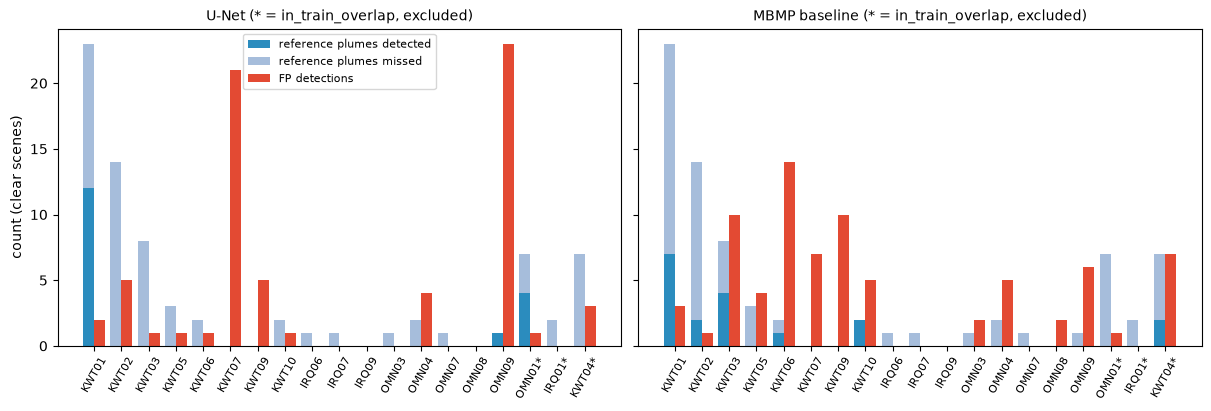

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained", sharey=True)
for ax, m in zip(axes, ("unet", "mbmp"), strict=True):
    p = per[m]
    x = np.arange(len(p))
    ax.bar(x - 0.2, p.detected, 0.4, label="reference plumes detected", color="#2b8cbe")
    ax.bar(x - 0.2, p.fn, 0.4, bottom=p.detected, label="reference plumes missed", color="#a6bddb")
    ax.bar(x + 0.2, p.fp_dets, 0.4, label="FP detections", color="#e34a33")
    labels = [s + ("*" if o else "") for s, o in zip(p.site_id, p.in_train_overlap, strict=True)]
    ax.set_xticks(x, labels, rotation=60, fontsize=8)
    name = {"unet": "U-Net", "mbmp": "MBMP baseline"}[m]
    ax.set_title(f"{name} (* = in_train_overlap, excluded)", fontsize=10)
axes[0].set_ylabel("count (clear scenes)")
axes[0].legend(fontsize=8)
fig.savefig(FIG / "04_gulf_by_site.png", dpi=150)

## False positives by cause (eligible sites, heuristic fixed before evaluation)

Order: VIIRS fire within 2 km and 12 h but beyond the 750 m mask (`flare_nearby`); scene cloud or shadow
fraction above 1% (`cloud_edge`); mean B12 under the detection above the chip's 90th percentile
(`bright_surface`); otherwise `unknown`. The cloud test is scene-level, so `cloud_edge` is an upper bound.

In [8]:
pd.DataFrame({m: R[m]["fp_by_cause_eligible"] for m in ("unet", "mbmp")}).fillna(0).astype(int)

,unet,mbmp
cloud_edge,29,22
unknown,26,25
bright_surface,8,6
flare_nearby,1,16


## Failure gallery (U-Net)

Chosen by a fixed rule, not by eye: the largest FP detection at each of the 5 eligible sites with the
most FPs, and the first FN (by date) at each of the 4 eligible sites with the most FNs. Panels: true colour
(B4, B3, B2), MBMP multi-pass dR (blue = negative = possible CH4), U-Net probability with detections
outlined (red = FP, cyan = other). The green cross marks the reference plume location (FN rows).

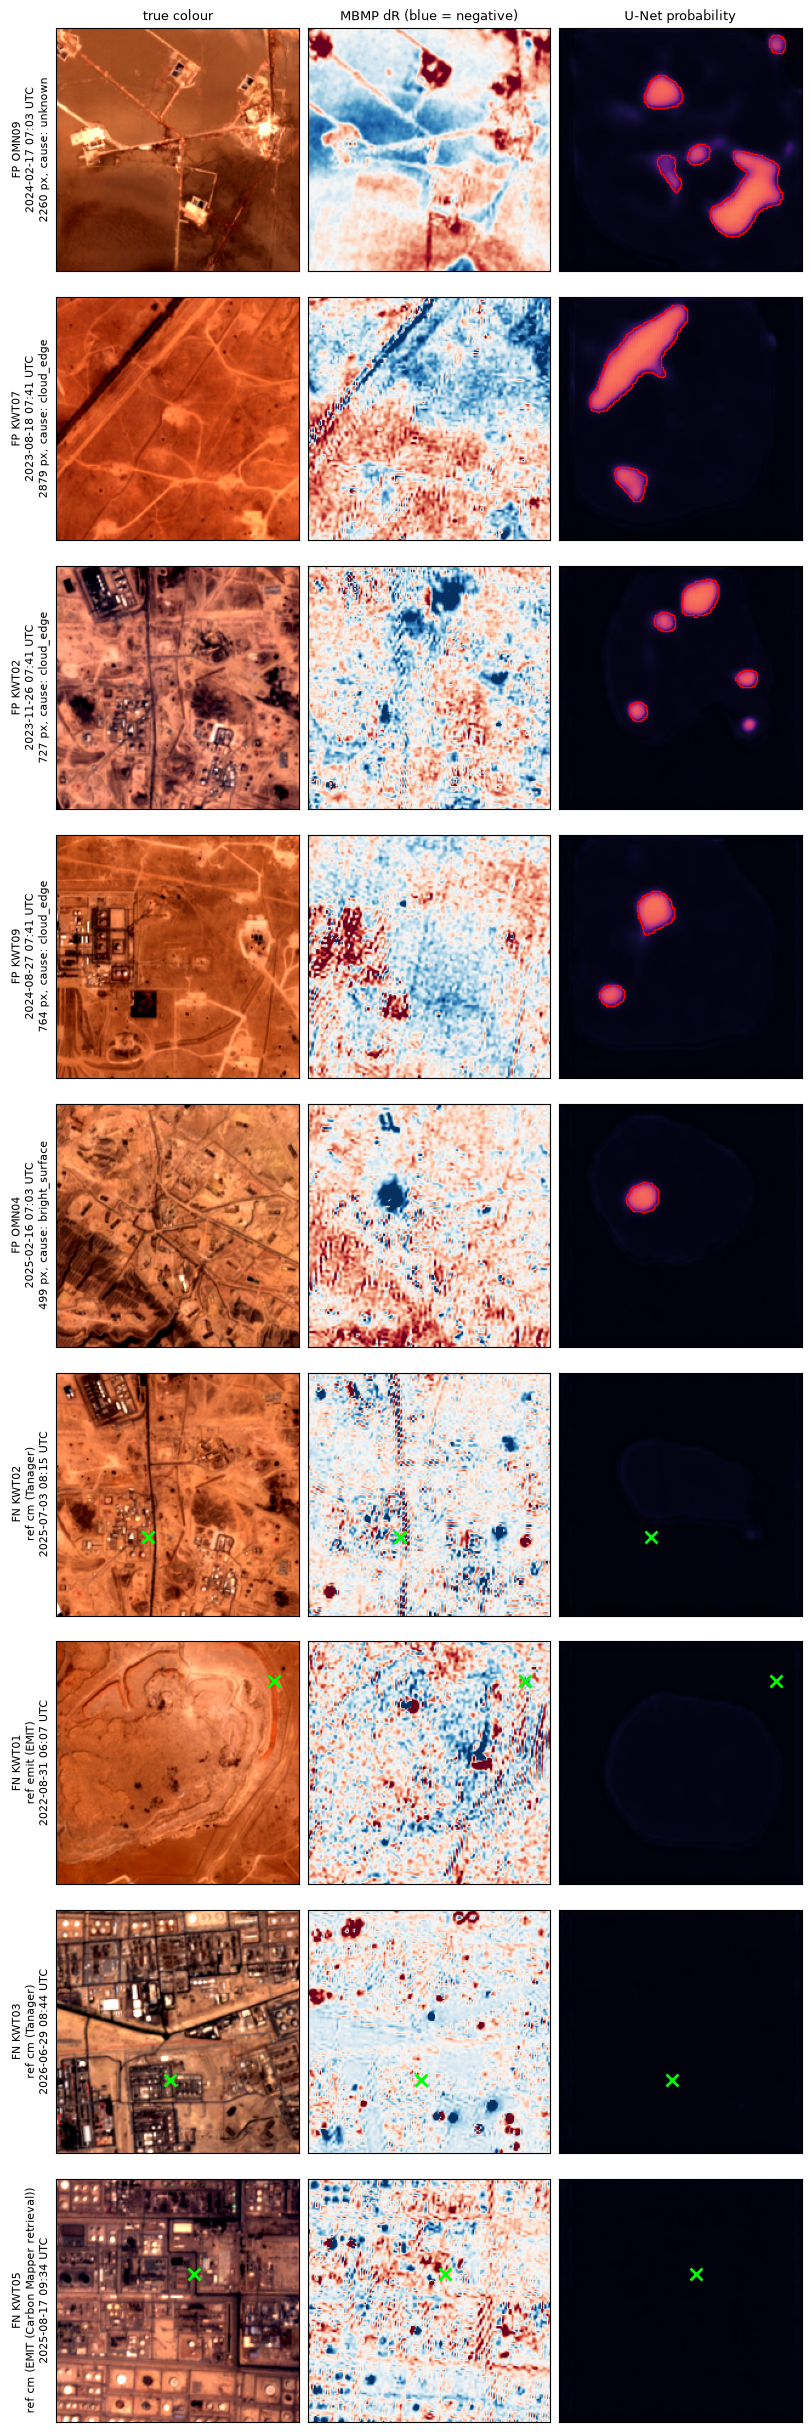

In [9]:
sc = pd.read_parquet(resolve_path(CFG["paths"]["scenes_table"]))
sc["date"] = pd.to_datetime(sc.date).dt.date
sc_by = sc.set_index("scene_id")
paths = sc.set_index(["site_id", "date"]).chip_path
det = pd.read_parquet(EV / "detections_unet.parquet")
gj = json.loads(resolve_path(CFG["paths"]["sites_geojson"]).read_text())
sites = pd.DataFrame([f["properties"] for f in gj["features"]])
elig = set(sites.loc[~sites.in_train_overlap, "site_id"])

fp = det[det.scene_clear & ~det.flare_masked & (det.match_status == "fp") & det.site_id.isin(elig)]
fp_pick = [
    fp[fp.site_id == s].sort_values("area_px").iloc[-1] for s in fp.site_id.value_counts().index[:5]
]
fn = ref[(ref.outcome == "fn") & ref.site_id.isin(elig)].sort_values("datetime_utc")
fn_pick = [fn[fn.site_id == s].iloc[0] for s in fn.site_id.value_counts().index[:4]]


def load(scene_id):
    s = sc_by.loc[scene_id]
    with rasterio.open(s.chip_path) as src:
        dn, tr, epsg = src.read().astype(float) / 1e4, src.transform, src.crs.to_epsg()
    dr = None
    if pd.notna(s.ref_scene_date):
        with rasterio.open(paths[(s.site_id, pd.Timestamp(s.ref_scene_date).date())]) as src:
            rf = src.read().astype(float) / 1e4
        ok = (dn > 0).all(0) & (rf > 0).all(0)

        def g(a, b):
            return np.where(ok, a[BANDS.index(b)], np.nan)

        dr = mbmp.multi_pass(g(dn, "B11"), g(dn, "B12"), g(rf, "B11"), g(rf, "B12"))
    pred = resolve_path(f"data/predictions/{s.site_id}/{s.date:%Y%m%d}.npz")
    prob = np.load(pred)["prob_u8"] / 255
    return dn, dr, prob, tr, epsg


def rgb(dn):
    x = np.stack([dn[BANDS.index(b)] for b in ("B4", "B3", "B2")], -1)
    lo, hi = np.nanpercentile(x, [2, 98])
    return np.clip((x - lo) / (hi - lo), 0, 1)


def to_px(lon, lat, tr, epsg):
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    return ~tr * (x, y)


def panel(axrow, scene_id, title, mark=None):
    dn, dr, prob, tr, epsg = load(scene_id)
    axrow[0].imshow(rgb(dn))
    if dr is not None:
        v = np.nanpercentile(np.abs(dr), 98)
        axrow[1].imshow(dr, cmap="RdBu", vmin=-v, vmax=v)
    axrow[2].imshow(prob, cmap="magma", vmin=0, vmax=1)
    for d in det[det.scene_id == scene_id].itertuples():
        poly = wkt.loads(d.geometry_wkt)
        for geom in getattr(poly, "geoms", [poly]):
            xs, ys = geom.exterior.xy
            cr = [to_px(a, b, tr, epsg) for a, b in zip(xs, ys, strict=True)]
            axrow[2].plot(
                *zip(*cr, strict=True), color="red" if d.match_status == "fp" else "cyan", lw=1
            )
    if mark is not None:
        c, r = to_px(*mark, tr, epsg)
        for ax in axrow:
            ax.plot(c, r, "x", color="lime", ms=9, mew=2)
    for ax in axrow:
        ax.set_xticks([])
        ax.set_yticks([])
    axrow[0].set_ylabel(title, fontsize=8)


n = len(fp_pick) + len(fn_pick)
fig, axes = plt.subplots(n, 3, figsize=(8, 2.7 * n), layout="constrained")
for i, d in enumerate(fp_pick):
    when = f"{d.datetime_utc:%Y-%m-%d %H:%M} UTC"
    panel(axes[i], d.scene_id, f"FP {d.site_id}\n{when}\n{d.area_px} px, cause: {d.fp_cause}")
captions = []
for j, r in enumerate(fn_pick):
    cand = sc[(sc.site_id == r.site_id) & (sc.obscured_frac < 0.2)].copy()
    cand["dt"] = (pd.to_datetime(cand.datetime_utc, utc=True) - r.datetime_utc).abs()
    best = cand.sort_values("dt").iloc[0]
    when = f"{r.datetime_utc:%Y-%m-%d %H:%M} UTC"
    title = f"FN {r.site_id}\nref {r.source} ({r.instrument})\n{when}"
    panel(axes[len(fp_pick) + j], best.scene_id, title, mark=(r.lon, r.lat))
axes[0, 0].set_title("true colour", fontsize=9)
axes[0, 1].set_title("MBMP dR (blue = negative)", fontsize=9)
axes[0, 2].set_title("U-Net probability", fontsize=9)
fig.savefig(FIG / "04_failure_gallery.png", dpi=130)

**Gallery observations.** OMN09: probability blobs sit on facility pads where the MBMP field is
strongly negative, i.e. surface change between the target and reference dates, not a plume shape. KWT07: an
elongated detection follows a diagonal linear stripe in MBMP (a road or pipeline edge artefact). In the
four FN rows the U-Net probability is near zero and MBMP shows no clear negative signal at the reference
location; several are Tanager plumes that may be below the Sentinel-2 detection limit. The model follows
the MBMP channel closely (see the Turkmenistan transfer check in PROGRESS.md), so MBMP artefacts carry
into its detections.

## Reading

- On 16 eligible Gulf sites the U-Net (trained on Turkmenistan) does not beat the MBMP baseline. Plume
  recall 0.220 [0.000, 0.414] vs 0.271 [0.125, 0.412]; precision 0.190 [0.000, 0.462] vs 0.188
  [0.071, 0.312]; about 45 to 48 FP detections per 100 clear EMIT true-negative scenes for both.
- U-Net detections concentrate at one site: KWT01 holds 12 of the 13 detected reference plumes. Most
  other sites have none. This matches the site-disjoint CH4Net result (Phase 2): performance is driven by
  a few sites, with wide site-level CIs.
- FPs cluster at KWT07 and OMN09 (21 and 23 FP detections), several per scene. The cause heuristic puts
  most U-Net FPs in `cloud_edge` (scene-level, an upper bound) and `unknown`.
- References are mostly Carbon Mapper (Tanager); only 4 EMIT plumes had a clear S2 scene within +-1 day.
  Many airborne or Tanager-detected plumes are likely below the Sentinel-2 detection limit, so this
  evaluation cannot separate model misses from plumes S2 cannot see.
- Caveats: model inputs are a mapping to CH4Net's uint8 display scale fitted on Turkmenistan; CH4Net's
  MBMP preprocessing is not fully reproduced; one frozen operating point; 16 sites.